# Notebook 03: Reading Dwell Time Dynamics & Parametric Log-Normal Fit

## 1. Statistical Model
Active on-device reading duration $T > 0$ exhibits strong positive skew modeled by a Log-Normal density:
$$f(t; \mu, \sigma) = \frac{1}{t \sigma \sqrt{2\pi}} \exp\!\left(-\frac{(\ln t - \mu)^2}{2\sigma^2}\right)$$
Below we estimate $(\hat{\mu}, \hat{\sigma})$ directly via Maximum Likelihood Estimation on real `interactions.csv` dwell logs and compare affinity vs non-affinity sessions.

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
from scipy import stats

df = pd.read_csv(os.path.join(DATA_DIR, "interactions.csv"))
dwell = df["dwell_time_sec"].clip(lower=0.5).values

shape, loc, scale = stats.lognorm.fit(dwell, floc=0)
mu_hat = float(np.log(scale))
sigma_hat = float(shape)
ks_stat, ks_p = stats.kstest(dwell, "lognorm", args=(shape, loc, scale))

print(f"Empirical Mean Dwell Time   : {dwell.mean():.2f} s")
print(f"Empirical Median Dwell Time : {np.median(dwell):.2f} s")
print(f"90th Percentile Dwell Time  : {np.percentile(dwell, 90):.2f} s")
print(f"Log-Normal MLE Parameters   : mu = {mu_hat:.4f}, sigma = {sigma_hat:.4f}")
print(f"Affinity Mean Dwell         : {df[df['is_affinity']==1]['dwell_time_sec'].mean():.2f} s")
print(f"Non-Affinity Mean Dwell     : {df[df['is_affinity']==0]['dwell_time_sec'].mean():.2f} s")
print(f"KS Statistic                : {ks_stat:.4f}")

Empirical Mean Dwell Time   : 61.99 s
Empirical Median Dwell Time : 55.60 s
90th Percentile Dwell Time  : 130.30 s
Log-Normal MLE Parameters   : mu = 3.5927, sigma = 1.2532
Affinity Mean Dwell         : 80.42 s
Non-Affinity Mean Dwell     : 5.49 s
KS Statistic                : 0.1713


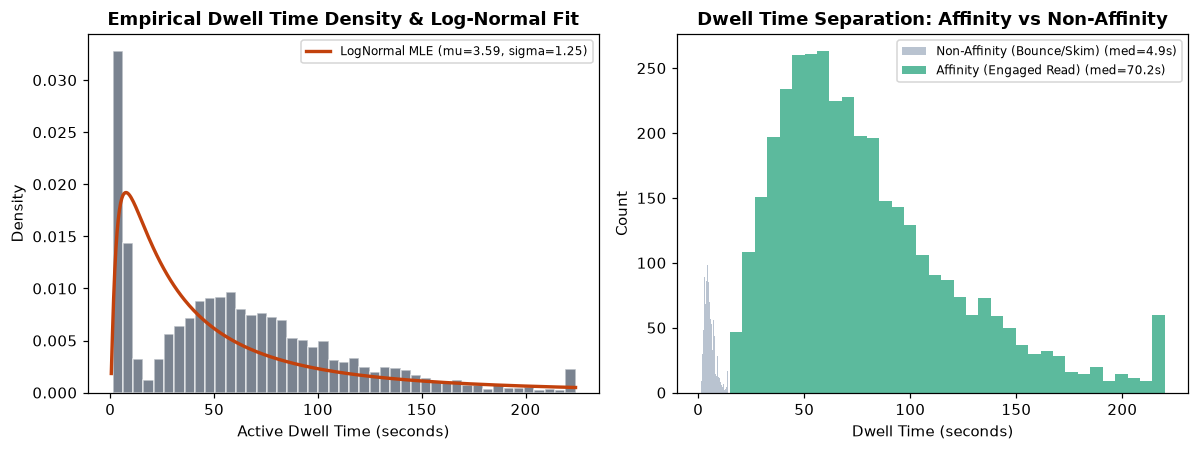

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = np.linspace(0.5, np.percentile(dwell, 99), 400)
pdf = stats.lognorm.pdf(x, shape, loc=loc, scale=scale)
axes[0].hist(np.clip(dwell, 0, x.max()), bins=45, density=True, alpha=0.65, color="#334155", edgecolor="white")
axes[0].plot(x, pdf, color="#c2410c", lw=2.2, label=f"LogNormal MLE (mu={mu_hat:.2f}, sigma={sigma_hat:.2f})")
axes[0].set_title("Empirical Dwell Time Density & Log-Normal Fit", fontweight="bold")
axes[0].set_xlabel("Active Dwell Time (seconds)")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8)

for val, lbl, col in [(0, "Non-Affinity (Bounce/Skim)", "#94a3b8"), (1, "Affinity (Engaged Read)", "#059669")]:
    sub = df[df["is_affinity"] == val]["dwell_time_sec"]
    axes[1].hist(np.clip(sub, 0, 220), bins=35, alpha=0.65, label=f"{lbl} (med={sub.median():.1f}s)", color=col)
axes[1].set_title("Dwell Time Separation: Affinity vs Non-Affinity", fontweight="bold")
axes[1].set_xlabel("Dwell Time (seconds)")
axes[1].set_ylabel("Count")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()